# The Whiten population balance step by step: the breakage matrix, the circulating mass and the product

**Question:** How many times does a unit of feed pass through the nip at the S01 setting, what is the product the balance returns, and how does the recirculation grow as the setting closes?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic and topic 02
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- build the breakage matrix B on the sieve grid and check that it is strictly lower triangular with columns that conserve mass;
- write the chamber balance, see why it needs a linear solve, and solve it;
- read the solution as the mass that reaches the breakage zone, and from it the number of nip events per unit of feed;
- derive the product from the solution and confirm that the engine's own solver returns the same numbers;
- follow the recirculation as the closed-side setting tightens.

## Setup

Numpy and matplotlib; the linear algebra of the notebook is the engine's own.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are `assemble_chamber`, which builds the classification vector and the breakage matrix of an operating point exactly as the engine does, the engine's LU solver and conditioning proxy, the Whiten solver itself, and the sieve and oracle utilities.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import Operating, evaluate, grid_edges, grid_mid
from pipeline.model.crusher.linalg import solve_lu, cond_proxy
from pipeline.model.crusher.whiten import assemble_chamber, whiten_solve
from pipeline.model.crusher.sieve import to_psd, size_at_passing
from pipeline.oracles import mass_closure
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The reference case S01 again. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads the operating point and runs the engine once to get the feed distribution on the grid.

In [2]:
# Read S01, run the engine once for its feed on the grid, and fix the grid constants
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
result = evaluate(op)
edges, mids = grid_edges(), grid_mid()
K = len(mids)
feed = np.array(result.feed.mass)
print("classes:", K, "| feed mass:", feed.sum().round(12), "| F80", round(result.f80, 2), "mm")

classes: 28 | feed mass: 1.0 | F80 126.03 mm


## Method

**Step 1, the two matrices.** The balance needs the selection and the breakage on the same grid. The selection is the classification evaluated at each class mid-size, a vector $c$. The breakage is the matrix $B$ whose entry $B_{ij}$ is the mass fraction of broken class-$j$ material that reports to the finer class $i$; it is built from the appearance function of notebook 01, integrated over the class edges, with each column renormalised so that broken mass is conserved. Because fragments are always finer than their parent, only classes below $j$ receive mass: $B$ is strictly lower triangular. The cell asks `assemble_chamber` for both. It performs the construction of notebook 01 on the engine's grid, the specific energy, t10 and the appearance weight for $B$ and the K1, K2, K3 constants of the setting for $c$, and returns the pair $(c, B)$ that `evaluate` itself solves. The cell then checks the three properties of $B$.

In [3]:
# Ask the pipeline for c and B of S01 and check B's structure
c, B = assemble_chamber(op)
column_error = np.abs(B.sum(axis=0)[:-1] - 1).max()
n_one, n_mid, n_zero = int((c == 1).sum()), int(((c > 0) & (c < 1)).sum()), int((c == 0).sum())
print("shapes of c and B:", c.shape, B.shape)
print("entries on or above the diagonal:", np.count_nonzero(np.triu(B)))
print("largest column-sum error (all columns but the last):", column_error)
print("classes with C = 1, between 0 and 1, and 0:", n_one, n_mid, n_zero)

shapes of c and B: (28,) (28, 28)
entries on or above the diagonal: 0
largest column-sum error (all columns but the last): 4.440892098500626e-16
classes with C = 1, between 0 and 1, and 0: 4 2 22


The figure shows $B$ as an image on a logarithmic colour scale: a lower triangle whose bright band lies just under the diagonal for the coarse classes, because a particle breaks mostly into fragments a few classes finer, and fades towards the bottom-left, where the large size ratios are rare. The right panel shows $c$ against the class index.

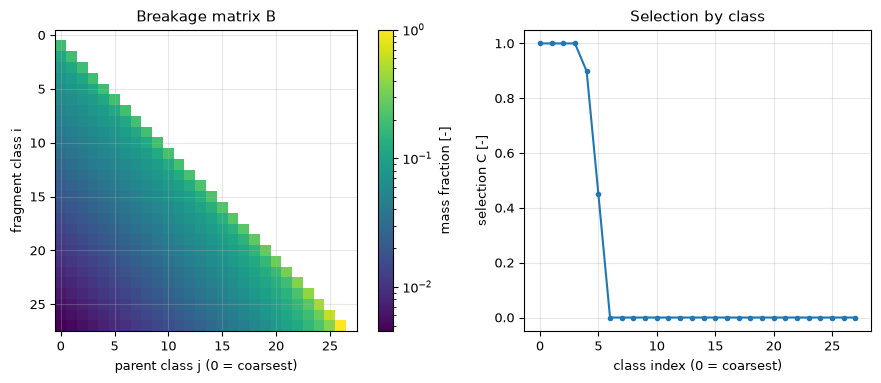

In [4]:
# Show B on a logarithmic colour scale and c against the class index
fig, (left, right) = plt.subplots(1, 2, figsize=(9.2, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
shown = left.imshow(np.where(B > 0, B, np.nan), norm="log", cmap="viridis")
left.set_xlabel("parent class j (0 = coarsest)")
left.set_ylabel("fragment class i")
left.set_title("Breakage matrix B")
fig.colorbar(shown, ax=left, label="mass fraction [-]")
right.plot(range(K), c, "o-", ms=3)
right.set_xlabel("class index (0 = coarsest)")
right.set_ylabel("selection C [-]")
right.set_title("Selection by class")
fig.tight_layout()
plt.show()

The image confirms the structure the printout reported: nothing on or above the diagonal and a smooth fan below it. The right panel shows that C is 1 for the first four classes, falls through two classes where the material is sorted by chance, and is 0 from there on: only coarse material is nipped, and the fines that are already smaller than K1 leave directly. The picture does not show the balance; the next step writes it.

**Step 2, the chamber balance.** Let $x$ be the mass per class that reaches the breakage zone, counting every visit. It arrives from two sources: the fresh feed $f$, and the fragments of what was nipped earlier. A fraction $c_j$ of class $j$ is nipped, and $B$ distributes it, so

$$x = f + B\,C\,x \quad\Longleftrightarrow\quad (I - B C)\,x = f$$

with $C = \mathrm{diag}(c)$. What is not nipped leaves as product: $p = (I - C)\,x = (I - C)(I - BC)^{-1} f$ (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf; Napier-Munn et al., 1996). $B C$ is strictly lower triangular, so $I - BC$ has a unit diagonal and determinant 1: the system is never singular. The cell assembles $M = I - BC$, prints its diagonal and its conditioning proxy, and solves for $x$ with the engine's LU routine.

In [5]:
# Assemble M = I - B C, look at its diagonal and conditioning, and solve M x = f with the engine's LU routine
M = np.eye(K) - B * c[None, :]
x = np.array(solve_lu(M.ravel().tolist(), feed.tolist(), K))
print("diagonal of M, min and max:", np.diag(M).min(), np.diag(M).max())
print("conditioning proxy:", round(cond_proxy(M.ravel().tolist(), K), 4))
print("mass reaching the breakage zone, per unit of feed:", x.sum().round(4))
print("nip events per unit of feed (sum of c x):", (c * x).sum().round(4))

diagonal of M, min and max: 1.0 1.0
conditioning proxy: 1.517
mass reaching the breakage zone, per unit of feed: 1.8858
nip events per unit of feed (sum of c x): 0.8858


The solution has a direct reading. Per unit of fresh feed, 1.8858 units of mass reach the breakage zone, so each unit of feed is, on average, nipped 0.8858 times: the first visit of a coarse particle breaks it, the fragments that are still above the selection range come back and are nipped again, and so on. The recirculation is why the setting changes the product more than a single breakage event would suggest. The product follows from $x$.

**Step 3, the product and the check.** The product is the part of $x$ that is not nipped, $p = (1 - c) \odot x$, and its total is the feed total because the solve conserved the mass. The engine's own solver, `whiten_solve`, does the same in one call. The cell computes the product from $x$, compares it with the engine's, and states the mass closure through the oracle, which compares the product total with the feed total without using the solver.

In [6]:
# Product from the solution, against the engine's own solver, and the mass closure from the oracle
product = (1 - c) * x
engine = whiten_solve(c.tolist(), B.ravel().tolist(), feed.tolist(), K)
print("largest difference to the engine's product:", np.abs(product / product.sum() - np.array(engine.product)).max())
print("mass closure, oracle:", mass_closure(feed.tolist(), product.tolist()), "| engine:", engine.mass_closure)
print("P80", round(size_at_passing(to_psd(edges, product.tolist()), 0.8), 3), "mm | engine", round(result.p80, 3), "mm")

largest difference to the engine's product: 2.7755575615628914e-17
mass closure, oracle: 0.0 | engine: 3.3306690738754696e-16
P80 27.698 mm | engine 27.698 mm


The three views of the solution sit in one figure: the fresh feed $f$, the mass $x$ that reaches the breakage zone, and the product $p$. The gap between $x$ and $f$ is the recirculated mass, and the gap between $x$ and $p$ is what is nipped.

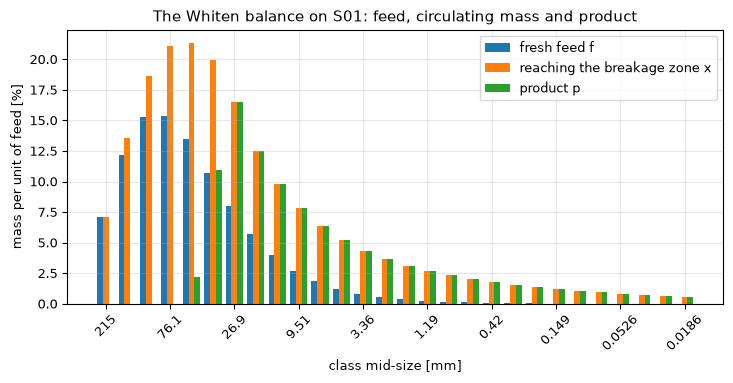

class mid-sizes where x exceeds f [mm]: [152.2, 107.6, 76.1, 53.8, 38.1, 26.9, 19.0, 13.5, 9.5, 6.7, 4.8, 3.4, 2.4, 1.7, 1.2, 0.8, 0.6, 0.4, 0.3, 0.2, 0.1, 0.1, 0.1, 0.1, 0.0, 0.0, 0.0]
classes where the product is zero: 4


In [7]:
# Bar chart of the feed, the mass reaching the breakage zone and the product, per class
position = np.arange(K)
series = ((-0.27, feed, "fresh feed f"), (0, x, "reaching the breakage zone x"), (0.27, product, "product p"))
fig, ax = plt.subplots()
for shift, values, label in series:
    ax.bar(position + shift, values * 100, 0.27, label=label)
ax.set_xticks(position[::3], [f"{m:.3g}" for m in mids[::3]], rotation=45)
ax.set_xlabel("class mid-size [mm]")
ax.set_ylabel("mass per unit of feed [%]")
ax.set_title("The Whiten balance on S01: feed, circulating mass and product")
ax.legend()
fig.tight_layout()
plt.show()
recirculated = [round(m, 1) for m, a, b in zip(mids, x, feed) if a > b + 1e-9]
print("class mid-sizes where x exceeds f [mm]:", recirculated)
print("classes where the product is zero:", int((product == 0).sum()))

In the coarsest class the bars of $x$ and $f$ coincide, since no fragment can come back above the feed's top size; in every class below it $x$ is higher than $f$ by the recirculated fragments, as the printed list of classes shows. The product $p$ is zero in the four classes that are always nipped and carries all of its mass below them. The figure does not tell how the product depends on the setting, because it is drawn at one; the next step moves it.

**Step 4, recirculation against the setting.** The cell repeats the construction for closed-side settings from 40 to 160 percent of S01's, asking `assemble_chamber` for the classification of each setting (the breakage matrix does not depend on the setting and stays the same $B$), solves each system with the same LU routine and records the nip events per unit of feed and the product P80. A tighter setting selects smaller particles, so more fragments qualify for a second nip.

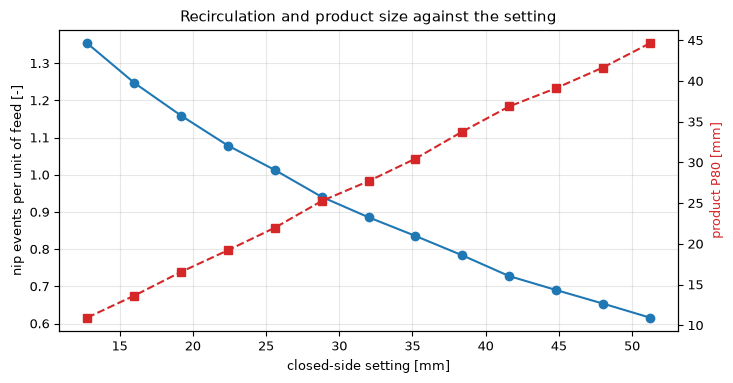

nip events at the tightest and the widest setting: 1.353 0.616
P80 at the tightest and the widest setting [mm]: 10.95 44.62


In [8]:
# Repeat the solve for a range of closed-side settings: nip events per unit of feed and product P80
settings = op.css_mm * np.linspace(0.4, 1.6, 13)
nips, p80s = [], []
for css in settings:
    cc, _ = assemble_chamber(replace(op, css_mm=float(css)))
    xx = np.array(solve_lu((np.eye(K) - B * cc[None, :]).ravel().tolist(), feed.tolist(), K))
    nips.append((cc * xx).sum())
    p80s.append(size_at_passing(to_psd(edges, ((1 - cc) * xx).tolist()), 0.8))
fig, ax = plt.subplots()
ax.plot(settings, nips, "o-")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("nip events per unit of feed [-]")
twin = ax.twinx()
twin.plot(settings, p80s, "s--", color="tab:red")
twin.set_ylabel("product P80 [mm]", color="tab:red")
twin.grid(False)
ax.set_title("Recirculation and product size against the setting")
fig.tight_layout()
plt.show()
print("nip events at the tightest and the widest setting:", round(nips[0], 3), round(nips[-1], 3))
print("P80 at the tightest and the widest setting [mm]:", round(p80s[0], 2), round(p80s[-1], 2))

Tightening the setting from 160 to 40 percent of S01's raises the nip events from 0.62 to 1.35 per unit of feed and brings P80 down from 44.62 mm to 10.95 mm, a factor of four, so a tight crusher does its work in several visits rather than one. This is the mechanism behind the capacity and power trade-offs of topic 04: more nips per tonne are more energy per tonne. The curve is smooth, with no regime change inside the range: the model does not predict choking, it flags it separately through the regime logic of the engine.

**Step 5, how far the balance can be pushed.** The unit diagonal of $I - BC$ says the system is solvable at any setting, and the conditioning proxy and the mass closure are the numbers that would show trouble if it were not. The cell asks the engine for both at ten settings from 1 mm to 140 mm, the last one wider than the F80 of the feed, and prints the regime and validity the engine assigns.

In [9]:
# Conditioning proxy, mass closure and regime of the engine for ten settings, from very tight to wider than F80
wide_range = [evaluate(replace(op, css_mm=float(css))) for css in (1, 2, 4, 8, 16, 32, 64, 100, 126, 140)]
for r in wide_range:
    print(f"CSS {r.op.css_mm:5.0f} mm  cond {r.cond_estimate:.3f}  closure {r.mass_closure:.1e}",
          f" P80 {r.p80:7.2f} mm  {r.regime:12s} valid={r.valid}")
worst_closure = max(r.mass_closure for r in wide_range)
worst_cond = max(r.cond_estimate for r in wide_range)
print("largest closure:", f"{worst_closure:.1e}", "| largest conditioning proxy:", round(worst_cond, 3))

CSS     1 mm  cond 1.831  closure 5.6e-16  P80    1.83 mm  choke        valid=True
CSS     2 mm  cond 1.807  closure 5.6e-16  P80    2.53 mm  choke        valid=True
CSS     4 mm  cond 1.763  closure 7.8e-16  P80    3.99 mm  choke        valid=True
CSS     8 mm  cond 1.700  closure 5.6e-16  P80    7.04 mm  choke        valid=True
CSS    16 mm  cond 1.621  closure 5.6e-16  P80   13.63 mm  choke        valid=True
CSS    32 mm  cond 1.517  closure 3.3e-16  P80   27.70 mm  choke        valid=True
CSS    64 mm  cond 1.378  closure 3.3e-16  P80   55.41 mm  choke        valid=True
CSS   100 mm  cond 1.274  closure 2.2e-16  P80   81.41 mm  choke        valid=True
CSS   126 mm  cond 1.208  closure 3.3e-16  P80   98.13 mm  choke        valid=True
CSS   140 mm  cond 1.164  closure 5.6e-16  P80  103.45 mm  pass-through valid=False
largest closure: 7.8e-16 | largest conditioning proxy: 1.831


The conditioning proxy stays between 1.16 and 1.83 and the closure under 1e-15 at every setting, tight or wide, so the numerics never break down: a bad answer from the engine is never a failed solve. What changes at 140 mm is the physics, not the algebra: the setting exceeds F80 (126 mm), the engine assigns the pass-through regime and marks the point invalid, because a crusher set wider than its feed does not break it. The balance would still return a number, and the validity flag is what keeps it from being read as a prediction.

The tight end has no such guard. The first row of the output reports a closed-side setting of 1 mm on a secondary cone fed at F80 126 mm as valid, in the choke regime: the validity flag does not bound the tight end, the engine has no minimum setting, and the repository holds no sourced minimum to give it one. A reader should not take a row at a setting far below what a cone can physically be set to as a prediction because the flag is True; this limit belongs to the engine, not to the balance.

## Results

**Answer:** at the S01 setting one unit of fresh feed sends 1.8858 units of mass to the breakage zone, so it is nipped 0.8858 times on average, and the balance returns a product with P80 = 27.698 mm, the same as the engine's, with a difference to the engine's product of 2.8e-17 and a mass closure of 0.0 by the oracle (3.3e-16 by the engine). Closing the setting to 40 percent of S01's raises the nip events to 1.353 and brings P80 down to 10.95 mm, against 0.616 and 44.62 mm at 160 percent. The validity flag marks the wide end (CSS 140 mm, pass-through) but not the tight end: CSS 1 mm is reported valid.

The structure figure shows the strictly lower triangular matrix and the selection in two panels; the bar chart shows the three masses; the last figure the recirculation against the setting. A validator would conclude that the Whiten balance is solved exactly, since the independent oracle closes the mass to machine precision and the stepwise solution agrees with the engine's solver to 1e-16, and that the model's response to the setting runs through the recirculation. What these checks do not show is that the model's B and C are right for a given plant: they are the published forms with the engine's constants, and the real surveys of topic 05 are where they meet a measurement.

## Summary

The crusher model is one linear system: $(I - BC)\,x = f$, solved exactly and without ever forming an inverse, then read as product and as recirculation. The solution tells how many times the material is nipped, which is the lever the setting pulls. The stepwise solve agrees with the pipeline's own solver; the notebook that follows samples the same B and C with the particle-replacement rule that discrete-element crusher models use, and shows that the balance is the expectation of that rule.

## References

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193